# Deskew parameter validation

Five deskew configurations plus an untreated baseline on the exact same 100 IAM and 100 Bentham validation lines as the denoising study (seed 42). Source revisions, model checkpoint, generation options and source indices are restored from that study. No training or test evaluation.

Labels state the maximum correction angle and angle step in degrees: `deskew_max5_step0.5` searches from -5° to +5° at 0.5° increments. The anchor is max10/step0.5; other configurations change one parameter. Search limits: 5°, 10°, 15°; steps at 10°: 0.25°, 0.5°, 1°. The projection-profile estimator uses Otsu thresholding internally, then rotates original image pixels with bicubic interpolation, white fill and an expanded canvas. It corrects line rotation, not character slant.

Shared input adaptation: preserve IAM grayscale and composite Bentham RGBA onto white RGB, equally for baseline and deskew. Text normalization collapses whitespace and retains case/punctuation. Selection uses the equal-dataset mean corpus CER, with WER as a tie-breaker and baseline eligible. Also report per-dataset winners. These are subset-validation results, not a final test performance estimate.

Results are saved under results/validation/deskew/<UTC study ID>/. Rerun only the evaluation cell to resume in this session.

In [1]:
import sys
from pathlib import Path
import json
import random
from datetime import datetime, timezone
from importlib.metadata import version
import numpy as np
import torch

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'src/load_dataset/iam.py').exists())
sys.path.insert(0, str(ROOT))
from src.load_dataset.iam import load_iam_dataset
from src.load_dataset.bentham import load_bentham_dataset, REVISION, ARCHIVES
from src.models.trocr import TrOCRRecognizer
from src.validation.deskew import configurations, evaluate, summarize

# Explicit reference pins this comparison to the completed denoising study.
REFERENCE = ROOT / 'results/validation/denoising/20261112T000633091905Z/metadata.json'
reference = json.loads(REFERENCE.read_text())
SEED = reference['seed']
BATCH_SIZE = reference['batch_size']
indices = reference['sample_indices']
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
assert reference['bentham_revision'] == REVISION
full_iam = load_iam_dataset('validation', revision=reference['iam_revision'])
full_bentham = load_bentham_dataset('validation')
assert {'iam': len(full_iam), 'bentham': len(full_bentham)} == reference['full_split_sizes']
iam = full_iam.select(indices['iam']).add_column('id', [f'sample_{i}' for i in indices['iam']])
bentham = full_bentham.select(indices['bentham'])
assert len(iam) == len(bentham) == 100
print('Validation subsets:', len(iam), len(bentham))
print('Modes:', iam[0]['image'].mode, bentham[0]['image'].mode)
print('Columns:', iam.column_names, bentham.column_names)

Ignoring part of dataset_info from the dataset card: The `splits` field in YAML is malformed or missing the name/num_examples/num_bytes fields


Validation subsets: 100 100
Modes: L RGBA
Columns: ['image', 'text', 'id'] ['id', 'image', 'text']


In [2]:
model = TrOCRRecognizer(checkpoint=reference['model']['checkpoint'],
    revision=reference['model']['revision'], device=reference['model']['device'],
    generation_kwargs=reference['model']['generation_kwargs'])
configs = configurations()
OUTPUT = ROOT / 'results/validation/deskew' / datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')
OUTPUT.mkdir(parents=True)
metadata = {'seed': SEED, 'split': 'validation', 'batch_size': BATCH_SIZE,
    'sample_indices': indices, 'sample_count_per_dataset': 100, 'deskew_run_count': 5,
    'reference_study': str(REFERENCE.relative_to(ROOT)),
    'iam_revision': reference['iam_revision'], 'bentham_revision': REVISION,
    'bentham_archive_sha256': ARCHIVES, 'full_split_sizes': reference['full_split_sizes'],
    'datasets': {name: {'count': len(ds), 'fingerprint': ds._fingerprint, 'columns': ds.column_names} for name, ds in [('iam', iam), ('bentham', bentham)]},
    'model': model.to_config(),
    'configurations': {name: step.to_config() if step else None for name, step in configs.items()},
    'selection': 'lowest equal-dataset mean corpus CER; WER tie-breaker; baseline eligible',
    'normalization': 'collapse whitespace, retain case and punctuation',
    'input_adaptation': 'RGBA white composite; preserve L/RGB',
    'scope': 'seeded validation subset parameter search, not final test evaluation',
    'versions': {p: version(p) for p in ['torch', 'transformers', 'datasets', 'huggingface-hub', 'Pillow', 'numpy', 'pandas', 'jiwer', 'opencv-python-headless', 'matplotlib']}}
(OUTPUT / 'metadata.json').write_text(json.dumps(metadata, indent=2))
print('Output:', OUTPUT)
print(json.dumps(metadata['configurations'], indent=2))

W1111 19:22:42.843000 13399 .venv/lib/python3.13/site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/478 [00:00<?, ?it/s]

[transformers] VisionEncoderDecoderModel LOAD REPORT from: microsoft/trocr-base-handwritten
Key                         | Status  | 
----------------------------+---------+-
encoder.pooler.dense.weight | MISSING | 
encoder.pooler.dense.bias   | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Output: /Users/vmendoza/Documents/Lakehead/RM/COMP-5112-Research-Methodology/results/validation/deskew/20261112T002245100371Z
{
  "baseline": null,
  "deskew_max5_step0.5": {
    "name": "deskew",
    "enabled": true,
    "max_angle": 5,
    "angle_step": 0.5,
    "estimator": "otsu_projection_difference",
    "resampling": "bicubic",
    "expand": true,
    "fill": "white"
  },
  "deskew_max10_step0.5": {
    "name": "deskew",
    "enabled": true,
    "max_angle": 10,
    "angle_step": 0.5,
    "estimator": "otsu_projection_difference",
    "resampling": "bicubic",
    "expand": true,
    "fill": "white"
  },
  "deskew_max15_step0.5": {
    "name": "deskew",
    "enabled": true,
    "max_angle": 15,
    "angle_step": 0.5,
    "estimator": "otsu_projection_difference",
    "resampling": "bicubic",
    "expand": true,
    "fill": "white"
  },
  "deskew_max10_step0.25": {
    "name": "deskew",
    "enabled": true,
    "max_angle": 10,
    "angle_step": 0.25,
    "estimator": "otsu_projec

In [3]:
summaries = []
for name, transform in configs.items():
    for dataset_name, dataset in [('iam', iam), ('bentham', bentham)]:
        result = evaluate(dataset, dataset_name, model, name, transform, OUTPUT, BATCH_SIZE)
        summaries.append(result)
        print(result, flush=True)
        if len(summaries) >= 2:
            table, ranking, winners = summarize(summaries, OUTPUT)
assert len(summaries) == 12
assert all(row['sample_count'] == 100 for row in summaries)
table, ranking, winners = summarize(summaries, OUTPUT)
display(table, ranking, winners)

iam/baseline: 8/100
iam/baseline: 80/100
iam/baseline: 100/100
{'dataset': 'iam', 'configuration': 'baseline', 'sample_count': 100, 'cer': 0.011541072640868975, 'wer': 0.0438034188034188, 'preprocessing_seconds': 0.0017425860023649875, 'inference_seconds': 37.21988887400221}
bentham/baseline: 8/100
bentham/baseline: 80/100
bentham/baseline: 100/100
{'dataset': 'bentham', 'configuration': 'baseline', 'sample_count': 100, 'cer': 0.15963923337091318, 'wer': 0.2954796030871003, 'preprocessing_seconds': 0.03618874699986918, 'inference_seconds': 28.36162458599938}
iam/deskew_max5_step0.5: 8/100
iam/deskew_max5_step0.5: 80/100
iam/deskew_max5_step0.5: 100/100
{'dataset': 'iam', 'configuration': 'deskew_max5_step0.5', 'sample_count': 100, 'cer': 0.011767368182846799, 'wer': 0.041666666666666664, 'preprocessing_seconds': 1.363996666004823, 'inference_seconds': 29.36113499900057}
bentham/deskew_max5_step0.5: 8/100
bentham/deskew_max5_step0.5: 80/100
bentham/deskew_max5_step0.5: 100/100
{'dataset

,dataset,configuration,sample_count,cer,wer,preprocessing_seconds,inference_seconds,cer_delta_vs_baseline,wer_delta_vs_baseline
0,iam,baseline,100,0.011541,0.043803,0.001743,37.219889,0.000000,0.000000
1,bentham,baseline,100,0.159639,0.295480,0.036189,28.361625,0.000000,0.000000
2,iam,deskew_max5_step0.5,100,0.011767,0.041667,1.363997,29.361135,0.000226,-0.002137
3,bentham,deskew_max5_step0.5,100,0.162570,0.307607,1.126063,27.670116,0.002931,0.012128
4,iam,deskew_max10_step0.5,100,0.011767,0.041667,3.363200,29.439524,0.000226,-0.002137
5,bentham,deskew_max10_step0.5,100,0.163472,0.308710,2.410510,27.739292,0.003833,0.013230
6,iam,deskew_max15_step0.5,100,0.011767,0.041667,6.069851,29.434173,0.000226,-0.002137
7,bentham,deskew_max15_step0.5,100,0.162570,0.308710,3.958885,27.680267,0.002931,0.013230
8,iam,deskew_max10_step0.25,100,0.012673,0.044872,6.233951,29.299596,0.001131,0.001068
9,bentham,deskew_max10_step0.25,100,0.156032,0.299890,4.245054,27.943198,-0.003608,0.004410


,cer,wer
configuration,,
deskew_max10_step0.25,0.084352,0.172381
baseline,0.085590,0.169642
deskew_max10_step1,0.086719,0.171847
deskew_max5_step0.5,0.087169,0.174637
deskew_max15_step0.5,0.087169,0.175188
deskew_max10_step0.5,0.087620,0.175188


,dataset,configuration,sample_count,cer,wer,preprocessing_seconds,inference_seconds,cer_delta_vs_baseline,wer_delta_vs_baseline
0,bentham,deskew_max10_step0.25,100,0.156032,0.299890,4.245054,27.943198,-0.003608,0.00441
1,iam,baseline,100,0.011541,0.043803,0.001743,37.219889,0.000000,0.00000


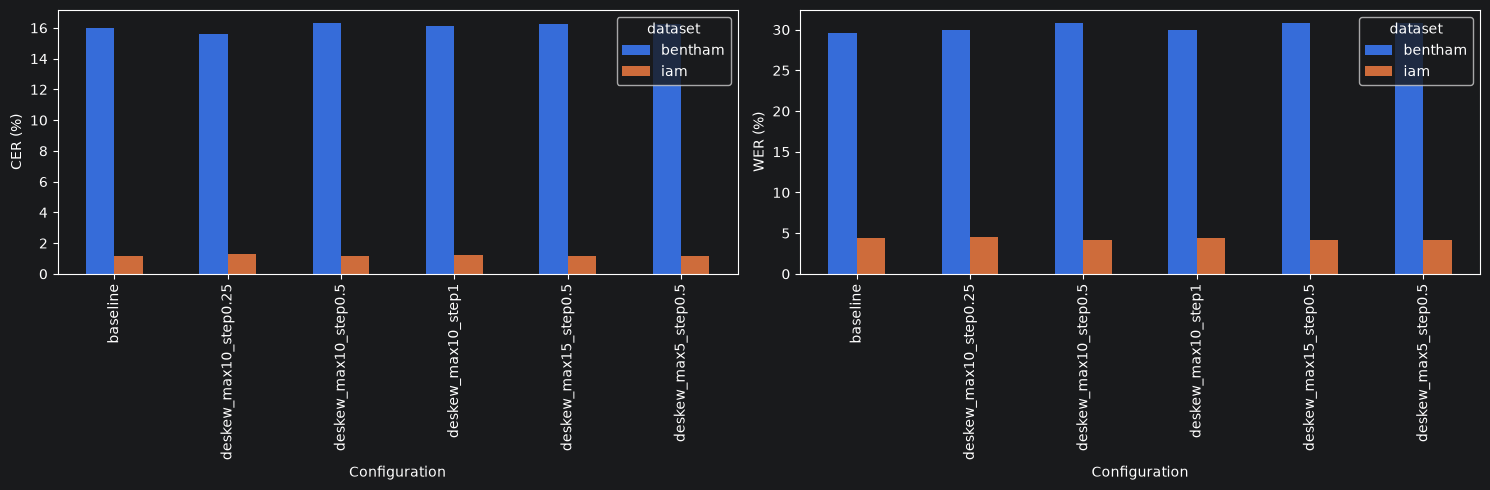

{
  "best_overall": "deskew_max10_step0.25",
  "best_deskew": "deskew_max10_step0.25",
  "deskew_parameters": {
    "name": "deskew",
    "enabled": true,
    "max_angle": 10,
    "angle_step": 0.25,
    "estimator": "otsu_projection_difference",
    "resampling": "bicubic",
    "expand": true,
    "fill": "white"
  },
  "criterion": "lowest equal-dataset mean corpus CER; WER tie-breaker; baseline eligible",
  "dataset_winners": [
    {
      "dataset": "bentham",
      "configuration": "deskew_max10_step0.25",
      "cer": 0.1560315670800451,
      "wer": 0.29988974641675853
    },
    {
      "dataset": "iam",
      "configuration": "baseline",
      "cer": 0.011541072640868975,
      "wer": 0.0438034188034188
    }
  ]
}
Subset validation optimum; confirm on validation data before freezing final test parameters.


In [4]:
import matplotlib.pyplot as plt
assert len(table) == 12 and table.sample_count.eq(100).all()
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, metric in zip(axes, ['cer', 'wer']):
    table.pivot(index='configuration', columns='dataset', values=metric).mul(100).plot.bar(ax=ax)
    ax.set_ylabel(metric.upper() + ' (%)')
    ax.set_xlabel('Configuration')
fig.tight_layout()
fig.savefig(OUTPUT / 'corpus_error_rates.png', dpi=160, bbox_inches='tight')
plt.show()
best_deskew = ranking.drop(index='baseline').index[0]
selection = {'best_overall': ranking.index[0], 'best_deskew': best_deskew,
    'deskew_parameters': configs[best_deskew].to_config(),
    'criterion': metadata['selection'],
    'dataset_winners': winners[['dataset', 'configuration', 'cer', 'wer']].to_dict('records')}
(OUTPUT / 'selection.json').write_text(json.dumps(selection, indent=2))
(OUTPUT / 'status.json').write_text(json.dumps({'status': 'complete', 'deskew_configurations': 5,
    'baseline_configurations': 1, 'validation_samples_per_dataset': 100,
    'completed_dataset_configuration_pairs': 12, 'seed': SEED}, indent=2))
print(json.dumps(selection, indent=2))
print('Subset validation optimum; confirm on validation data before freezing final test parameters.')